# Branching

<div class="alert alert-info">

**Summary**

This lesson constructs two stages whose continuation branches: the tenure choice of a durables model, whose branch a control selects, and a retiree's survival, whose branch a shock selects. You will inspect their fields, the law of motion of the branching block and the cards of the [[builder|builders]] the branches enter, draw the stage, a period and a [[trellis]] of the durables model, and see one stage the branch rules refuse. The lesson constructs; it evaluates and solves nothing.

</div>

<div class="alert alert-success">

**Relationship with other documents**

**Builds on** — [The stage as an object](../getting-started/01-the-stage.ipynb), [Distributions and the forward builders](../getting-started/03-distributions.ipynb) and [Periods and trellises](../getting-started/05-periods-and-trellises.ipynb): stages, measures, periods and trellises.

**Formal account** — [Operator algebra, section 5](../../docs/bellman-calculus/APPX-F-OPERATOR-ALGEBRA.md#5-branching): continuation alternatives with a label chosen by the policy or drawn from a conditional distribution.

**See also** — [The durables model](../../applications/durables/economics.md) and [the model of Cagetti and De Nardi](../../applications/cagetti-denardi-2006/economics.md): the two applications.

</div>

<div class="alert">

**Key terminology**

| Term | Meaning |
|---|---|
| label | A value of the control or the shock that selects a branch. |
| section | A law of motion with the label fixed. |
| card | The printed statement of what a piece of a stage denotes. |

</div>

A [[branch]] is one alternative of a discrete event, with a continuation state of its own: a household keeps its house or sells it; a retiree survives the year or dies. A [[stage]] branches when its block from the decision to the continuation holds one labeled block per alternative.

The lesson reads the two branching stage files, the durables model's recipe with every file the recipe names, and the file of the refused stage, given here by their paths from the repository root:

- `applications/durables/declaration/stages/tenure/tenure.bl`
- `applications/cagetti-denardi-2006/declaration/stages/retiree_death/retiree_death.bl`
- `applications/durables/declaration/spec.yml`
- `applications/durables/declaration/trellis.yml`
- `applications/durables/declaration/period.yml`
- `applications/durables/declaration/stages/keeper_cons/keeper_cons.bl`
- `applications/durables/declaration/stages/adjuster_cons/adjuster_cons.bl`
- `applications/durables/declaration/stages/bequest/bequest.bl`
- `applications/durables/declaration/calibration/durables.yml`
- `applications/durables/declaration/calibration/wage_schedule.yml`
- `applications/durables/declaration/settings/durables.yml`
- `applications/durables/declaration/stages/tenure/methods.bl`
- `applications/durables/declaration/stages/keeper_cons/methods.bl`
- `applications/durables/declaration/stages/adjuster_cons/methods.bl`
- `applications/durables/declaration/stages/bequest/methods.bl`
- `tutorials/topics/stages/plan_choice.bl`

The trellis it constructs reads each stage's methods file, the addition beside the stage file, and binds none of the recipe's parameter values or settings; the lesson writes no file.

## The two models

In the durables model of Dobrescu and Shanker (2026, "A fast upper envelope scan method for discrete-continuous dynamic programming", working paper, SSRN 4181302, Section 2.2), a household arrives at the tenure stage with financial assets $\mathrm{a}$, a house $\mathrm{h}$ and an income state $\mathrm{z}$. After the income shock $\varepsilon$ is drawn, it knows $\mathrm{a}_d$, $\mathrm{h}_d$ and $\mathrm{z}_d$ and chooses $\mathrm{d}$ in $\{\mathrm{keep}, \mathrm{adjust}\}$, with no other constraint. A keeper carries forward cash on hand $\mathrm{w}_{\mathrm{kp}} = R\,\mathrm{a}_d + y(\mathrm{z}_d)$, the depreciated house $\mathrm{h}_{\mathrm{kp}} = (1-\delta)\,\mathrm{h}_d$ and the income state; an adjuster sells the house and carries forward total wealth $\mathrm{w}_{\mathrm{adj}} = R\,\mathrm{a}_d + R_H(1-\delta)\,\mathrm{h}_d + y(\mathrm{z}_d)$ and the income state, with gross returns $R$ on assets and $R_H$ on a house sold, depreciation rate $\delta$ and income $y$. The stage after each branch chooses consumption and, for the adjuster, the new house.

In the model of Cagetti and De Nardi (2006, "Entrepreneurship, Frictions, and Wealth", *Journal of Political Economy* 114, Section III.E, equations (10) to (14)), a retiree holds assets $\mathrm{a}$, and the working and entrepreneurial abilities $\mathrm{y}$ and $\theta$ of a possible offspring are drawn before the decision. Nothing is chosen: after the decision perch the retiree survives the year with probability $\pi_o$ (Section III.A) and keeps the assets, or dies and leaves them to the offspring, whose utility the parent weights by $\eta$; $\beta$ is the discount factor.

The first code cell imports the collection's set-up module, `checkout`, and the functions the lesson calls, from `bellman.stage`, `bellman.period` and `bellman.trellis`.

In [1]:
import checkout
from bellman.period import diagram_period
from bellman.stage import elaborate_stage, load_stage
from bellman.trellis import diagram_trellis, elaborate_trellis, load_recipe

## The tenure stage

The header of the block `dcsn_to_cntn` declares the control `d : !ctrl @ {keep, adjust}`, and the block holds one nested block per **label**, a value of `d`, each writing its branch's fields. The block `cntn_to_dcsn` selects between the two branch values by the tuple indexed by the label, `(V_kp[>], V_adj[>])[d]`, and `policy` maximizes over the same tuple. The next cell prints the file.

In [2]:
print(load_stage("applications/durables/declaration/stages/tenure/tenure.bl")["stage"]["text"])

@stage: tenure

Age := {20, …, 71}

R   : ℝ₊₊       :: ["gross return on financial assets"]
R_H : ℝ₊₊       :: ["gross return on housing, received when the house is sold"]
δ   : [0,1)     :: ["depreciation rate of housing"]
ρ_z : (0,1)     :: ["persistence of log income"]
σ_z : ℝ₊        :: ["standard deviation of the innovation to log income"]
Y   : Age → ℝ₊        :: ["earnings per unit of the income state at the age of the period"]
y_R : Age → ℝ₊        :: ["income that does not depend on the income state at the age of the period"]

ε : ℝ
ε ~ N(0, 1)

[id=arvl_to_dcsn, (a : ℝ₊, h : ℝ₊₊, z : ℝ₊₊, ε) : !arvl -> (a_d : ℝ₊, h_d : ℝ₊₊, z_d : ℝ₊₊) : !dcsn] {
    a_d = a
    h_d = h
    z_d = z^ρ_z*exp(σ_z*ε)                              :: [id=income_state]
}

[id=dcsn_to_cntn, (a_d, h_d, z_d, age_kp[>], age_adj[>], d : !ctrl @ {keep, adjust}) : !dcsn -> ()] {
    [label=keep, () -> (w_kp : ℝ₊₊, h_kp : ℝ₊₊, z_kp : ℝ₊₊) : !cntn] {
        w_kp = R*a_d + Y[age_kp[>]]*z_d + y_R[age_kp[>]] ::

The next cell constructs the stage and names it `tenure`, the name the file declares.

In [3]:
tenure = elaborate_stage(load_stage("applications/durables/declaration/stages/tenure/tenure.bl"))

The next cell lists its fields. The control `d` stands at the decision perch, its values the two labels, and the continuation perch holds the fields of the two branches with each branch's value. A continuation state is a state of one branch together with its label: the continuation state space is the **disjoint union** of the keeper's states and the adjuster's.

In [4]:
tenure.fields()

tenure:arvl:a         ≺ arvl  state  in ℝ₊
tenure:arvl:h         ≺ arvl  state  in ℝ₊₊
tenure:arvl:z         ≺ arvl  state  in ℝ₊₊
tenure:shck:ε         ≺→∼  shock  in ℝ
tenure:dcsn:a_d       ∼ dcsn  state  in ℝ₊
tenure:dcsn:h_d       ∼ dcsn  state  in ℝ₊₊
tenure:dcsn:z_d       ∼ dcsn  state  in ℝ₊₊
tenure:cntn:age_kp    ≻ cntn  value  constant  in Age
tenure:cntn:age_adj   ≻ cntn  value  constant  in Age
tenure:dcsn:d         ∼ dcsn  control  in {keep, adjust}
tenure:cntn:w_kp      ≻ cntn  state  in ℝ₊₊
tenure:cntn:h_kp      ≻ cntn  state  in ℝ₊₊
tenure:cntn:z_kp      ≻ cntn  state  in ℝ₊₊
tenure:cntn:w_adj     ≻ cntn  state  in ℝ₊₊
tenure:cntn:z_adj     ≻ cntn  state  in ℝ₊₊
tenure:cntn:V_kp      ≻ cntn  value  in ℝ
tenure:cntn:V_adj     ≻ cntn  value  in ℝ
tenure:dcsn:V         ∼ dcsn  value  in ℝ
tenure:dcsn:age       ∼ dcsn  value  constant  in Age
tenure:arvl:V         ≺ arvl  value  in ℝ
tenure:arvl:age       ≺ arvl  value  constant  in Age

## One law of motion at each label

`definitions.denote` prints the card of the declaration its key names. The block `dcsn_to_cntn` owns one law of motion $g_\succ$, whose arguments include the label and whose value is the tuple of the branches' continuation states indexed by $\mathrm{d}$. Its **section** at a label is the law with the label fixed, $g_{\mathrm{keep},\succ}(\cdot) = g_\succ(\cdot, \mathrm{keep})$; every builder below reads the law through its sections. The declared sets do not establish the condition that the keeper's cash on hand is positive, since assets and income may both be zero.

In [5]:
tenure.definitions.denote("tenure:g:dcsn_to_cntn")

STAGE tenure / LAW OF MOTION dcsn_to_cntn
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
Defines
  𝑔≻  : ℝ₊ × ℝ₊₊ × ℝ₊₊ × Age × Age × {keep, adjust}
          → (ℝ₊₊ × ℝ₊₊ × ℝ₊₊, ℝ₊₊ × ℝ₊₊)[d],
        (a_d, h_d, z_d, age_kp, age_adj, d)
          ↦ ((R · a_d + Y[age_kp] · z_d + y_R[age_kp], (1 − δ) · h_d, z_d),
             (R · a_d + R_H · (1 − δ) · h_d + Y[age_adj] · z_d + y_R[age_adj],
              z_d))[d]

Conditions
  R · a_d + Y[age_kp] · z_d + y_R[age_kp] ∈ ℝ₊₊
──────────────────────────────────────────────────────────────────────────────
Source  tenure.bl
  24  w_kp = R*a_d + Y[age_kp[>]]*z_d + y_R[age_kp[>]]
        :: [id=cash_on_hand]
  25  h_kp = (1 - δ)*h_d
        :: [id=housing_kept]
  26  z_kp = z_d
  29  w_adj = R*a_d + R_H*(1 - δ)*h_d + Y[age_adj[>]]*z_d + y_R[age_adj[>]]
        :: [id=total_wealth]
  30  z_adj = z_d

Definitions referenced
  Age   tenure:set:Age
  R     tenure:parameter:R
  R_H   tenure:parameter:R_H
  δ     tenure

## The decision builder

The decision builder `cntn_to_dcsn` gives the value $V$ at the decision. Its card states the operator at a policy: `At` names $d$, the function giving the label chosen at each decision state, and `Where` states the two sections. One pullback per branch composes that branch's value with its section; the aggregation applies the file's value line, taking its tuple's entry at the label $d$ chooses; the evaluation returns the value. The derivatives of $V$ in $\mathrm{a}_d$ and $\mathrm{h}_d$, which the consumption stages of the period before read, are stated by the two derivative lines of the addition `applications/durables/declaration/stages/tenure/methods.bl`, which the recipe names; the lesson constructs the stage from its file alone, so the card names no derivative.

The decision builder also returns the age on the keep branch minus one. It reads both branch ages because each forward section uses income for the age one year younger than the one supplied to that branch.

In [6]:
tenure.dcsn.builder.bwd.denote()

STAGE tenure / BACKWARD BUILDER cntn → dcsn (cntn_to_dcsn)
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
Signature
  in   𝑉_kp≻     : ℝ₊₊ × ℝ₊₊ × ℝ₊₊ → ℝ
       𝑉_adj≻    : ℝ₊₊ × ℝ₊₊ → ℝ
       𝑎𝑔𝑒_kp≻   : {()} → Age
       𝑎𝑔𝑒_adj≻  : {()} → Age
       ───────────────────────────────────────────────────────────────────────
  out  𝑉         : ℝ₊ × ℝ₊₊ × ℝ₊₊ → ℝ
       𝑎𝑔𝑒       : {()} → Age

At
  𝑑  : ℝ₊ × ℝ₊₊ × ℝ₊₊ → {keep, adjust}

Where
  𝑔_keep≻    : ℝ₊ × ℝ₊₊ × ℝ₊₊ × Age → ℝ₊₊ × ℝ₊₊ × ℝ₊₊,
               𝑔_keep≻(a_d, h_d, z_d, age_kp) =
                 (R · a_d + Y[age_kp] · z_d + y_R[age_kp], (1 − δ) · h_d, z_d)
  𝑔_adjust≻  : ℝ₊ × ℝ₊₊ × ℝ₊₊ × Age → ℝ₊₊ × ℝ₊₊,
               𝑔_adjust≻(a_d, h_d, z_d, age_adj)
                 = (R · a_d
                      + R_H · (1 − δ) · h_d
                      + Y[age_adj] · z_d
                      + y_R[age_adj],
                    z_d)

Operations
  1  Pullback:keep
     in: 𝑉_kp≻, 𝑎𝑔𝑒_kp≻             

## The selection at the policy

The policy builder, `tenure.dcsn.builder.policy`, gives $d$. After the same two pullbacks, `choice:Aggregation` maps a decision state and a label to the branch value at that label, and `choice:Argmax`, the operation of kind [`Argmax`](../../docs/Bellman-Sym/reference/operations.md#argmax) that the line `choice` forms, states that $d$ at each decision state lies in the set of labels maximizing it. The tuple is the value line's, entry for entry and in the same order. At a tie the set holds both labels; the card selects neither, and the numerical method must choose one.

In [7]:
tenure.dcsn.builder.policy.denote()

STAGE tenure / POLICY BUILDER policy
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
Signature
  in   𝑉_kp≻     : ℝ₊₊ × ℝ₊₊ × ℝ₊₊ → ℝ
       𝑉_adj≻    : ℝ₊₊ × ℝ₊₊ → ℝ
       𝑎𝑔𝑒_kp≻   : {()} → Age
       𝑎𝑔𝑒_adj≻  : {()} → Age
       ───────────────────────────────────────────────────────────────────────
  out  𝑑         : ℝ₊ × ℝ₊₊ × ℝ₊₊ → {keep, adjust}

Where
  𝑔_keep≻    : ℝ₊ × ℝ₊₊ × ℝ₊₊ × Age → ℝ₊₊ × ℝ₊₊ × ℝ₊₊,
               𝑔_keep≻(a_d, h_d, z_d, age_kp) =
                 (R · a_d + Y[age_kp] · z_d + y_R[age_kp], (1 − δ) · h_d, z_d)
  𝑔_adjust≻  : ℝ₊ × ℝ₊₊ × ℝ₊₊ × Age → ℝ₊₊ × ℝ₊₊,
               𝑔_adjust≻(a_d, h_d, z_d, age_adj)
                 = (R · a_d
                      + R_H · (1 − δ) · h_d
                      + Y[age_adj] · z_d
                      + y_R[age_adj],
                    z_d)

Operations
  1  Pullback:keep
     in: 𝑉_kp≻, 𝑎𝑔𝑒_kp≻                 out: 𝑉_kp≻ ∘ 𝑔_keep≻(·, ·, ·, 𝑎𝑔𝑒_kp≻)
     ──────────────────────────────────

## One measure per label

The forward builder `dcsn_to_cntn` carries a **measure** $\mu$, the distribution of households over the decision states, to the continuation states, one measure per label: $\mu_{\mathrm{keep},\succ}(B)$ is the mass of the decision states that the policy sends to `keep` and the keep section sends into the set $B$. Each household is on one branch, so the two masses add up to that of $\mu$ where each branch line writes into its declared set; the card lists the keeper's line under `Conditions`.

In [8]:
tenure.dcsn.builder.fwd.denote()

STAGE tenure / FORWARD BUILDER dcsn → cntn (dcsn_to_cntn)
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
Signature
  in   μ          : finite measure on ℝ₊ × ℝ₊₊ × ℝ₊₊
       ────────────────────────────────────────────────────────
  out  μ_keep≻    : finite measure on ℝ₊₊ × ℝ₊₊ × ℝ₊₊
       μ_adjust≻  : finite measure on ℝ₊₊ × ℝ₊₊

At
  𝑑  : ℝ₊ × ℝ₊₊ × ℝ₊₊ → {keep, adjust}

Where
  𝑔_keep≻    : ℝ₊ × ℝ₊₊ × ℝ₊₊ × Age → ℝ₊₊ × ℝ₊₊ × ℝ₊₊,
               𝑔_keep≻(a_d, h_d, z_d, age_kp) =
                 (R · a_d + Y[age_kp] · z_d + y_R[age_kp], (1 − δ) · h_d, z_d)
  𝑔_adjust≻  : ℝ₊ × ℝ₊₊ × ℝ₊₊ × Age → ℝ₊₊ × ℝ₊₊,
               𝑔_adjust≻(a_d, h_d, z_d, age_adj)
                 = (R · a_d
                      + R_H · (1 − δ) · h_d
                      + Y[age_adj] · z_d
                      + y_R[age_adj],
                    z_d)

Operations
  1  Pushforward
     in: μ                              out: μ_keep≻, μ_adjust≻
     ──────────────────────────────

## The drawings of the stage

The stage's `initial` holds its two **initial diagrams**, backward and forward, graphs whose framed regions are the blocks, each holding one box per line, and whose wires are fields; `initial.forward.diagram()` draws the forward one. The block `dcsn_to_cntn` holds one dashed frame per branch, `dcsn_to_cntn.keep` around the three keep lines and `dcsn_to_cntn.adjust` around the two adjust lines. A builders graph draws no such frame: there the branches appear as the pullbacks and the aggregation that the cards above list.

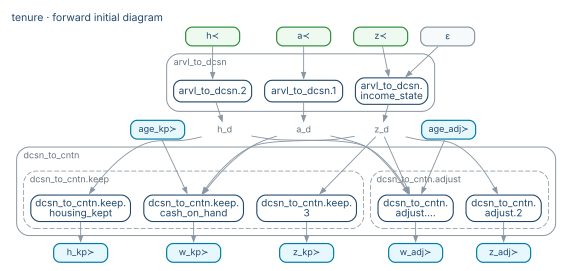

In [9]:
tenure.initial.forward.diagram()

## A branch a shock selects

The next cell constructs the retiree's stage and names it `retiree_death`, the name its file declares. The file writes its branches as `tenure.bl` does, with the labels `survive` and `die`, and its value line takes the expectation over the draw, `V = β*E_{s}((W_r[>], η*V_young[>])[s])`.

In [10]:
retiree_death = elaborate_stage(load_stage("applications/cagetti-denardi-2006/declaration/stages/retiree_death/retiree_death.bl"))

The next cell lists its fields. The label `s` is a shock drawn between the decision and the continuation, marked ∼→≻, whose values are the two labels; no field is a control. The survivor's branch writes the assets `a_rd_rt`, and the other the offspring's assets and abilities.

In [11]:
retiree_death.fields()

retiree_death:arvl:a_rd      ≺ arvl  state  in Xa
retiree_death:shck:y_n       ≺→∼  shock  in Y
retiree_death:shck:θ_n       ≺→∼  shock  in Θ
retiree_death:dcsn:a         ∼ dcsn  state  in Xa
retiree_death:dcsn:y         ∼ dcsn  state  in Y
retiree_death:dcsn:θ         ∼ dcsn  state  in Θ
retiree_death:shck:s         ∼→≻  shock  in {survive, die}
retiree_death:cntn:a_rd_rt   ≻ cntn  state  in Xa
retiree_death:cntn:a_rd_yc   ≻ cntn  state  in Xa
retiree_death:cntn:y_rd_yc   ≻ cntn  state  in Y
retiree_death:cntn:θ_rd_yc   ≻ cntn  state  in Θ
retiree_death:cntn:W_r       ≻ cntn  value  in ℝ
retiree_death:cntn:V_young   ≻ cntn  value  in ℝ
retiree_death:dcsn:V         ∼ dcsn  value  in ℝ
retiree_death:arvl:V         ≺ arvl  value  in ℝ

A shock that selects branches needs a distribution giving each label one probability, in the order of the labels, `Categorical` with one weight per label or `Bernoulli` over two; the rule `branch-law` refuses a label shock without such a distribution. The file's distribution gives `survive` the probability $\pi_o$ and `die` the probability $1 - \pi_o$.

In [12]:
retiree_death.definitions.denote("retiree_death:distribution:s")

STAGE retiree_death / DISTRIBUTION s
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
Defines
  s  ~ Categorical(π_o, 1 − π_o)
──────────────────────────────────────────────────────────────────────────────
Source  retiree_death.bl
  21  s ~ Categorical((π_o, 1 - π_o))
        :: ["surviving or dying, with probabilities in the order of the
        labels"]

Definitions referenced
  π_o   retiree_death:parameter:π_o
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

The decision builder's card has no `At` heading, since nothing is chosen, and the two sections under `Where`. The aggregation prints the value line as the file writes it.

In [13]:
retiree_death.dcsn.builder.bwd.denote()

STAGE retiree_death / BACKWARD BUILDER cntn → dcsn (cntn_to_dcsn)
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
Signature
  in   𝑊_r≻      : Xa → ℝ
       𝑉_young≻  : Xa × Y × Θ → ℝ
       ───────────────────────────────────────────────────────
  out  𝑉         : Xa × Y × Θ → ℝ

Where
  𝑔_survive≻  : Xa × Y × Θ → Xa,  𝑔_survive≻(a, y, θ) = 𝑔≻(a, y, θ, survive)
  𝑔_die≻      : Xa × Y × Θ → Xa × Y × Θ,  𝑔_die≻(a, y, θ) = 𝑔≻(a, y, θ, die)

Operations
  1  Pullback:survive
     in: 𝑊_r≻                           out: 𝑊_r≻ ∘ 𝑔_survive≻
     ─────────────────────────────────────────────────────────
     rule: (𝑊_r≻ ∘ 𝑔_survive≻)(a, y, θ) = 𝑊_r≻(𝑔_survive≻(a, y, θ))

  2  Pullback:die
     in: 𝑉_young≻                       out: 𝑉_young≻ ∘ 𝑔_die≻
     ─────────────────────────────────────────────────────────
     rule: (𝑉_young≻ ∘ 𝑔_die≻)(a, y, θ) = 𝑉_young≻(𝑔_die≻(a, y, θ))

  3  Aggregation
     in: (1), (2)                       out: 𝑉
     ────────────────

The definition of the aggregation's map, the value aggregator $G_\succ$, states the weighted sum the expectation denotes, with the distribution's weights: $V = \beta\,(\pi_o W_{\mathrm{r},\succ} + (1-\pi_o)\,\eta\,V_{\mathrm{young},\succ})$, each branch value read at the state its own section gives.

In [14]:
retiree_death.definitions.denote("retiree_death:G:cntn_to_dcsn")

STAGE retiree_death / VALUE AGGREGATOR cntn_to_dcsn
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
Defines
  𝐺≻  : ℝ × ℝ × Xa × Y × Θ → ℝ,
        (W_r≻, V_young≻, a, y, θ)
          ↦ β · (π_o · W_r≻ + (1 − π_o) · (η · V_young≻))

Conditions
  𝑉(a, y, θ) ∈ ℝ
──────────────────────────────────────────────────────────────────────────────
Source  retiree_death.bl
  41  V = β*E_{s}((W_r[>], η*V_young[>])[s])  :: [id=value]

Definitions referenced
  Xa    retiree_death:set:Xa
  Y     retiree_death:set:Y
  Θ     retiree_death:set:Θ
  β     retiree_death:parameter:β
  η     retiree_death:parameter:η
  π_o   retiree_death:parameter:π_o
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

## The branches in a period and a trellis

Each branch continues into a stage of its own: in each period of the durables model, `tenure` is followed by `keeper_cons` and `adjuster_cons`, the consumption stages of the two branches, and the terminal period adds `bequest`, which values the wealth left and keeps the supplied terminal age. Each consumption stage keeps its incoming age and sends it back to tenure through the named value pair in the period's connector. `load_recipe` reads the model's recipe with every file it names, and `elaborate_trellis` constructs every stage of every period with the addition its record names, binding no parameter value and no setting; the next cell names the trellis `durables_life_cycle`, as its file does.

In [15]:
durables_life_cycle = elaborate_trellis(load_recipe("applications/durables/declaration", "spec.yml"))

`diagram_period` draws the terminal period, `periods[0]`. The consumption stages begin at their decision perches, and the period's second [[connector]] joins the branch fields to their decision states, `w_kp`, `h_kp` and `z_kp` to the keeper's `w_d`, `h_d` and `z_d`, and `w_adj` and `z_adj` to the adjuster's `m` and `z_d`; both consumption stages reach the bequest through the first.

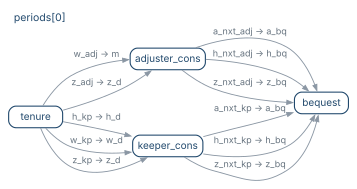

In [16]:
diagram_period(durables_life_cycle, 0)

`diagram_trellis` draws the listed periods, the terminal period at the right: here the first and the last two, labeled by their positions. The mapping `inter_connectors[0]` sends the continuation fields of both consumption stages of `periods[1]` to the arrival fields of the tenure stage of `periods[0]`: the two branches of one year meet at the next year's tenure choice.

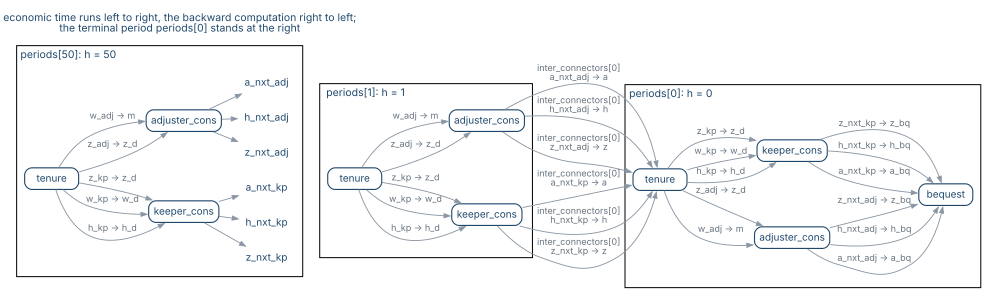

In [17]:
diagram_trellis(durables_life_cycle, periods=[0, 1, 50])

## A refusal

In the pension model of Dobrescu, Fan, Bateman, Newell, Ortmann and Thorp (2018, "Retirement savings: a tale of decisions and defaults", *The Economic Journal* 128), an employee chooses once between a defined-benefit and a defined-contribution plan, and wealth is unchanged by the choice. `plan_choice.bl` writes the plans as the branches `db` and `dc`; its policy maximizes over $(V_{\mathrm{db},\succ}, V_{\mathrm{dc},\succ} - u_p(t_0))$, but its value line is the expected maximum under taste shocks, a log-sum of the two. A branch a control selects is valued by the entry, at the policy's label, of the tuple the policy maximizes over, so the construction stops under the rule `branch-tuple-mismatch`.

In [18]:
elaborate_stage(load_stage("tutorials/topics/stages/plan_choice.bl"))

ConstructionError: tutorials/topics/stages/plan_choice.bl:42:5-42:220: the value line selects by no tuple indexed by 'j', and the policy line policy.choice maximizes over (V_db[>], V_dc[>] - 𝑢p(t_0)); write the value line as the tuple of the branch values indexed by 'j', and the policy's maximand as that tuple, in its order (address 'cntn_to_dcsn.value'; rule branch-tuple-mismatch)

The refusal names the value line and the rule it breaks. [The branching page](../../docs/Bellman-Sym/05-branching.md) admits two forms of a branch value: for a branch a control selects, the entry at the policy's label of the tuple the policy maximizes over; for a branch a shock selects, the expectation of the tuple over the label's distribution. The value line of `plan_choice.bl` is the expected maximum under extreme-value taste shocks (Rust, 1987, "Optimal replacement of GMC bus engines: an empirical model of Harold Zurcher", *Econometrica* 55(5); Iskhakov, Jørgensen, Rust and Schjerning, 2017, "The endogenous grid method for discrete-continuous dynamic choice models with (or without) taste shocks", *Quantitative Economics* 8(2)), a log-sum of the branch values, which is neither form, and so the construction refuses it.